# TP 2: Building self-attention step by step

In TP1 my bigram only saw the last character, so even a perfect table stopped at 2.45 nats. Here I build the operation that lets each position use the characters before it. I start from a plain average of the past and end with a head that learns which past tokens matter.

The diagram follows the four versions and the checks that tie them together.

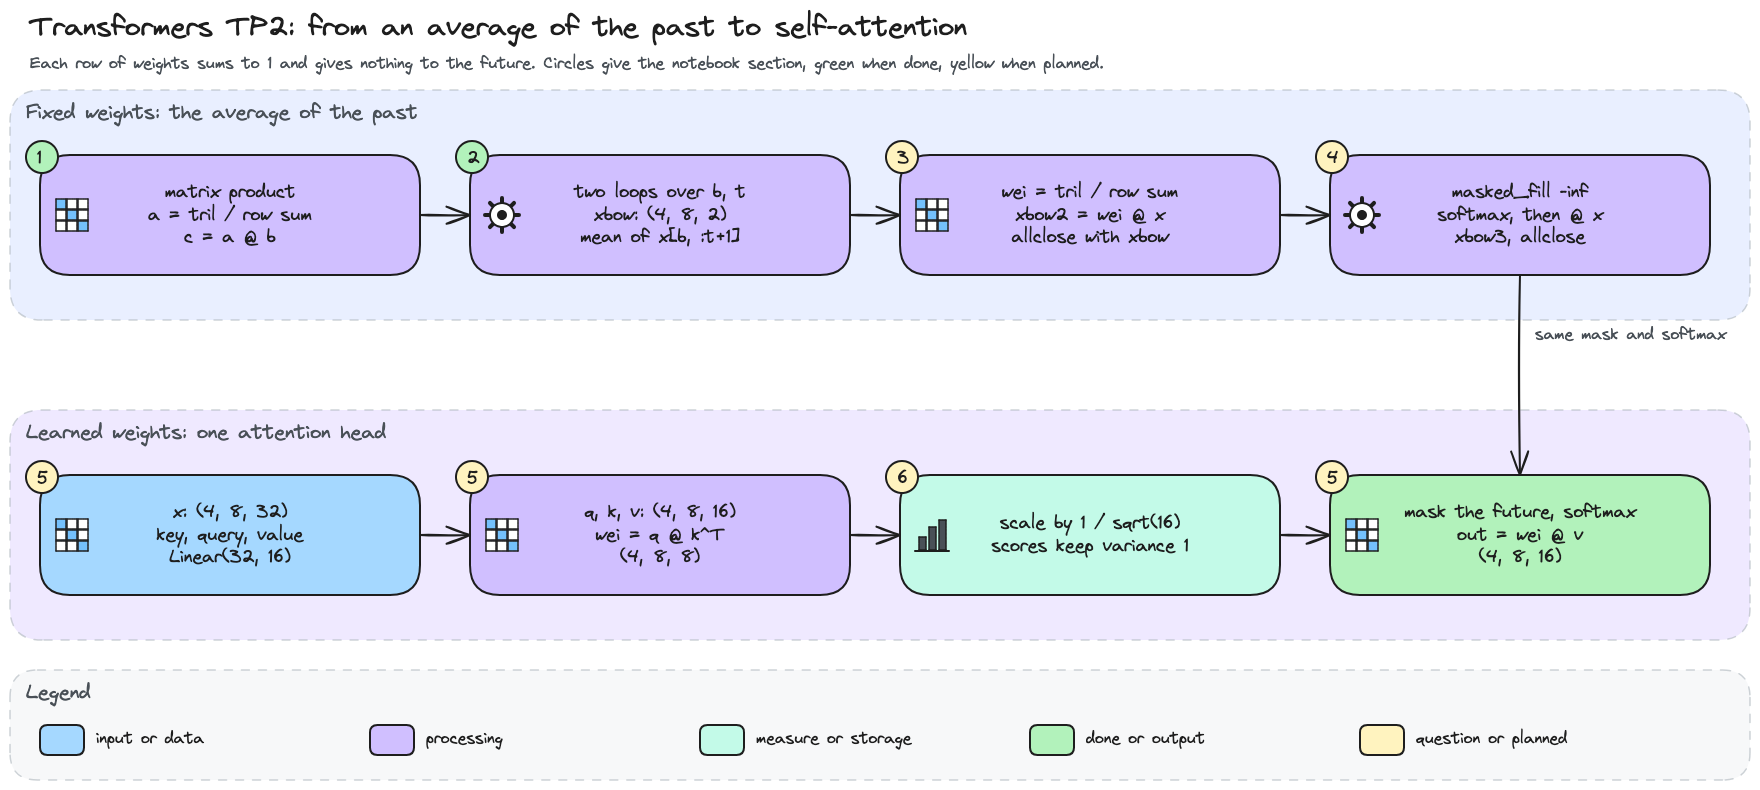

In [1]:
# Workflow diagram: from a fixed average of the past to one attention head (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp2_workflow.png', width=900))

## 0. My problem and what I carry over

I want each position of a sequence to collect information from the positions before it, and never from those after. I start from what TP1 taught me, and the diagram links each lesson to what it changes here.

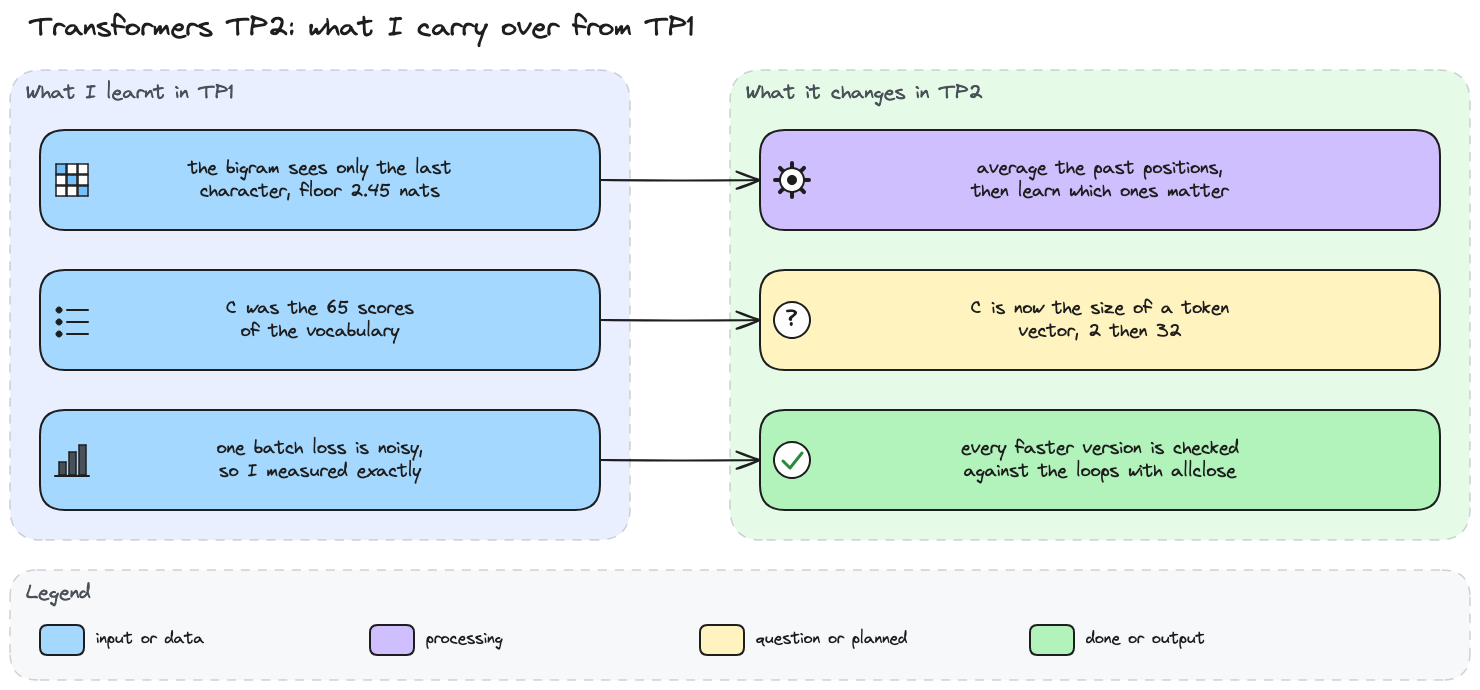

In [2]:
# What I carry over from TP1 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp2_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - A lower-triangular matrix with rows summing to 1 gives exactly the averages of my loops, because both compute the same weighted sum. Sections 2 and 3 check it with `torch.allclose`.
> - Filling the future with −∞ and applying softmax gives the same weights, since exp(−∞) = 0 and softmax divides by the row sum. Section 4 tests it.
> - With random keys and queries, the attention weights are no longer uniform, but each row still sums to 1 and gives nothing to the future. I look at it in section 5.
> - Without scaling, the variance of q·kᵀ grows with the head size, so softmax puts almost all the weight on one token. Section 6 measures this.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in TP1.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep every tensor on the CPU in this TP, because they are tiny and nothing is trained. I fix seed 42 once, and the handout cells also set their own seeds, so every random draw is the same at every run.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the handout cells set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Aggregate with a matrix product

Before any attention, I want to check that one row of a matrix can pick several vectors and weight them. A lower-triangular matrix whose rows sum to 1 should turn a matrix product into an average of the rows above. The diagram shows the small example and what I check.

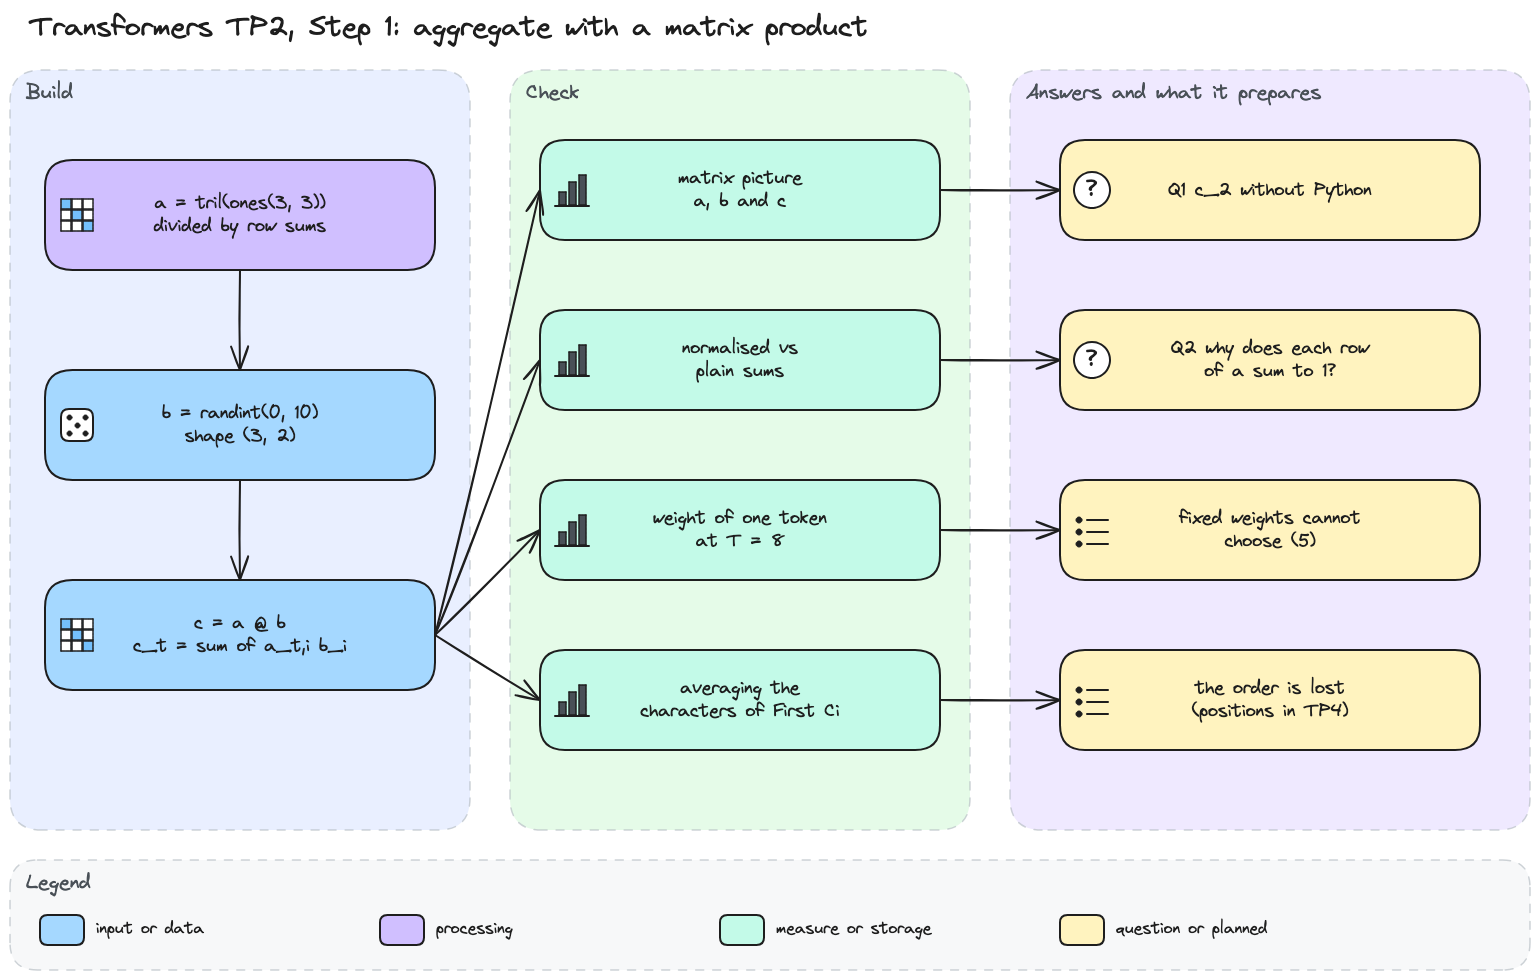

In [4]:
# Step 1 diagram: a, b and c, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step1.png', width=900))

In [5]:
# A lower-triangular matrix with rows summing to 1, a random matrix, and their product.
torch.manual_seed(42)

a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)

b = torch.randint(0, 10, (3, 2)).float()

c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


Row t of `a` puts the weight 1/(t+1) on the first t+1 positions and 0 after them, so `c = a @ b` should average the rows of `b`. What is c₂ without Python? I count rows from 1, as in the formula c_t = Σ a_t,i b_i. Row 2 of `a` is (1/2, 1/2, 0), so c₂ = ½ b₁ + ½ b₂ = ½ (2, 7) + ½ (6, 4) = (4, 5.5). The printed `c` agrees, on its row of index 1 in Python.

I draw the three matrices to see this choice row by row.

In [6]:
# Tools: draw a small matrix as a heatmap, with its values written in the cells.
import matplotlib.pyplot as plt


def show_matrix(ax: plt.Axes, matrix: torch.Tensor, title: str, digits: int = 2) -> None:
    """Heatmap of a 2D tensor with each value written in its cell."""
    values = matrix.detach().cpu()
    low, high = values.min().item(), values.max().item()
    ax.imshow(values, cmap='Blues', vmin=low, vmax=high + 0.6 * (high - low or 1))  # light cells
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            ax.text(col, row, f'{values[row, col]:.{digits}f}', ha='center', va='center',
                    fontsize=9)
    ax.set_xticks(range(values.shape[1]))
    ax.set_yticks(range(values.shape[0]))
    ax.set_title(title, fontsize=10)

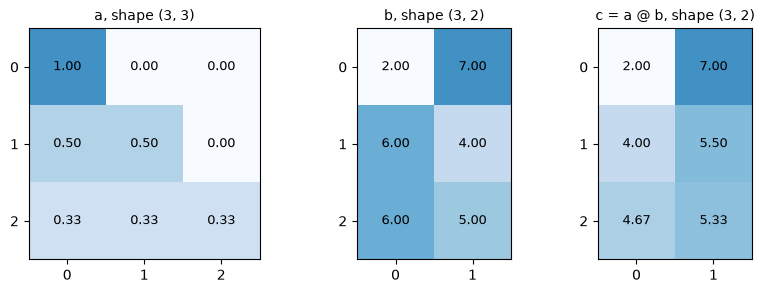

In [7]:
# How does a row of a pick the rows of b? The three matrices with their values.
fig, axes = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [3, 2, 2]})
for ax, matrix, title in ((axes[0], a, 'a, shape (3, 3)'), (axes[1], b, 'b, shape (3, 2)'),
                          (axes[2], c, 'c = a @ b, shape (3, 2)')):
    show_matrix(ax, matrix, title)
plt.show()

Each row of `a` lights up the rows of `b` it uses. The first row of `c` copies the first row of `b`, (2, 7), the second averages two rows into (4, 5.5), and the last averages all three into (4.67, 5.33). So a matrix product can pick vectors and weight them, which is all that averaging the past needs.

The rows of `a` were divided by their sum, and I want to see what that division changes.

Row sums of a: [1.0, 1.0, 1.0]
c, rows summing to 1: [[2.0, 7.0], [4.0, 5.5], [4.67, 5.33]]
Same product without the division: [[2.0, 7.0], [8.0, 11.0], [14.0, 16.0]]
Range of b per column: from [2.0, 4.0] to [6.0, 7.0]


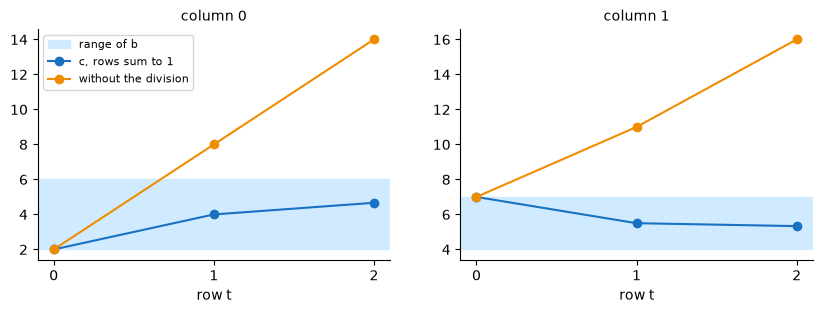

In [8]:
# Why should each row of a sum to 1? Row sums, then the same product without the division.
plain = torch.tril(torch.ones(3, 3)) @ b
rounded = lambda matrix: [[round(value, 2) for value in row] for row in matrix.tolist()]
print(f'Row sums of a: {a.sum(1).tolist()}')
print(f'c, rows summing to 1: {rounded(c)}')
print(f'Same product without the division: {rounded(plain)}')
print(f'Range of b per column: from {b.min(0).values.tolist()} to {b.max(0).values.tolist()}')

rows = torch.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for col, ax in enumerate(axes):
    ax.axhspan(b[:, col].min(), b[:, col].max(), color='#d0ebff', label='range of b')
    ax.plot(rows, c[:, col], marker='o', color='#1971c2', label='c, rows sum to 1')
    ax.plot(rows, plain[:, col], marker='o', color='#f08c00', label='without the division')
    ax.set_xticks(rows)
    ax.set_xlabel('row t')
    ax.set_title(f'column {col}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Why does each row of `a` sum to 1? Because each row was divided by the number of ones it holds, so the weights of a row form an average. Then `c` stays inside the range of `b`, between 2 and 6 in the first column and between 4 and 7 in the second. Without the division, the product gives running sums, (2, 7), then (8, 11), then (14, 16), which grow with t. A later position would get a bigger vector only because more tokens come before it.

With rows summing to 1, I now look at how much one past token weighs when the context grows.

Weight of the first token in each row: [1.0, 0.5, 0.333, 0.25, 0.2, 0.167, 0.143, 0.125]


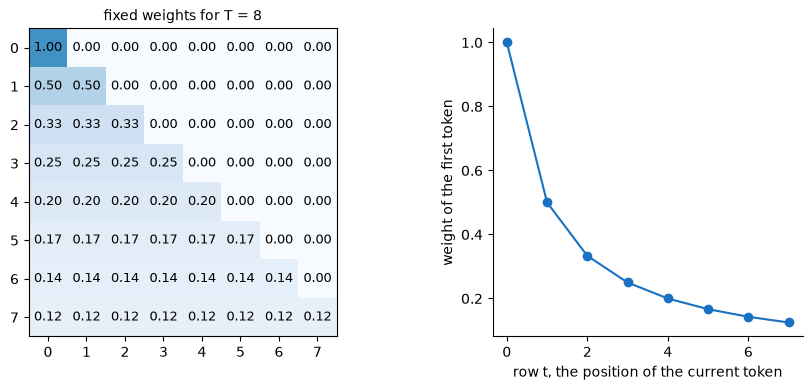

In [9]:
# With fixed weights, how much does one past token count as the context grows? T = 8.
T = 8
weights = torch.tril(torch.ones(T, T))
weights = weights / weights.sum(1, keepdim=True)
print(f'Weight of the first token in each row: {[round(w, 3) for w in weights[:, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [3, 2]})
show_matrix(axes[0], weights, 'fixed weights for T = 8')
axes[1].plot(range(T), weights[:, 0], marker='o', color='#1971c2')
axes[1].set_xlabel('row t, the position of the current token')
axes[1].set_ylabel('weight of the first token')
axes[1].spines[['top', 'right']].set_visible(False)
plt.show()

In each row, every visible token gets the same weight 1/(t+1), so the first token weighs 1, then 0.5, and only 0.125 in the last row. This weight depends only on the position, never on what the token contains. Fixed weights cannot decide that one past character matters more than another, and that is what the learned attention weights of section 5 will do.

To see what an average keeps from real text, I apply these weights to the first characters of the corpus.

Characters of the snippet: [' ', 'C', 'F', 'i', 'r', 's', 't']
Last row, share of each character: [0.125, 0.125, 0.125, 0.25, 0.125, 0.125, 0.125]
Same last row for the reversed snippet: True


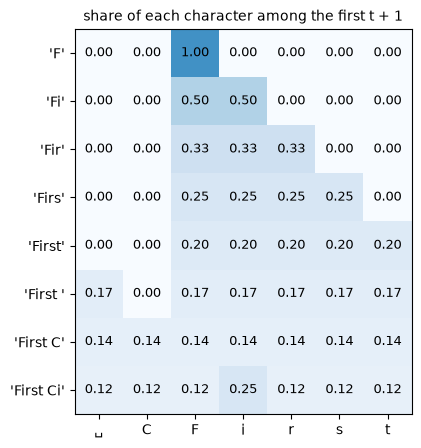

In [10]:
# What does an average of the past keep from real text? One-hot vectors of "First Ci", averaged.
snippet = "First Ci"
symbols = sorted(set(snippet))
one_hot = torch.zeros(len(snippet), len(symbols))
one_hot[torch.arange(len(snippet)), torch.tensor([symbols.index(ch) for ch in snippet])] = 1
averaged = weights @ one_hot
reversed_last = (weights @ one_hot.flip(0))[-1]  # the same characters in reverse order

print(f'Characters of the snippet: {symbols}')
print(f'Last row, share of each character: {[round(v, 3) for v in averaged[-1].tolist()]}')
print(f'Same last row for the reversed snippet: {torch.allclose(averaged[-1], reversed_last)}')

fig, ax = plt.subplots(figsize=(7, 5))
show_matrix(ax, averaged, 'share of each character among the first t + 1')
ax.set_xticks(range(len(symbols)), ['␣' if ch == ' ' else ch for ch in symbols])
ax.set_yticks(range(len(snippet)), [repr(snippet[:t + 1]) for t in range(len(snippet))])
plt.show()

Each row now gives the share of each character among the first t+1. In the last row, `i` has 0.25 because it appears twice in `First Ci`, and every other character has 0.125. So an average keeps which characters appeared and how often. It loses their order, since the reversed snippet gives the same last row. A model built only on averages could not tell `First` from `tsriF`, which is why TP4 adds the position of each token.

> *My conclusion:*
>
> A lower-triangular matrix whose rows sum to 1 turns a matrix product into an average of the rows above, so one product averages the whole past at once. The division keeps the result inside the range of the vectors, but the weights stay fixed at 1/(t+1) and the average forgets the order. Section 2 builds the same average with loops, as a reference for the faster versions.
>
> My answers to the two questions of this step:
>
> 1. c₂ = ½ b₁ + ½ b₂ = ½ (2, 7) + ½ (6, 4) = (4, 5.5).
> 2. Each row of `a` sums to 1 because it is divided by its number of ones, so every output is an average of the rows of `b` and keeps their scale.

## 2. Average only the past

For each sequence of the batch and each position t, I want the mean of all the tokens visible up to t, and none after. I write it first with two loops, slow but easy to check, so it becomes my reference for the faster versions. The diagram shows the loops and what I check.

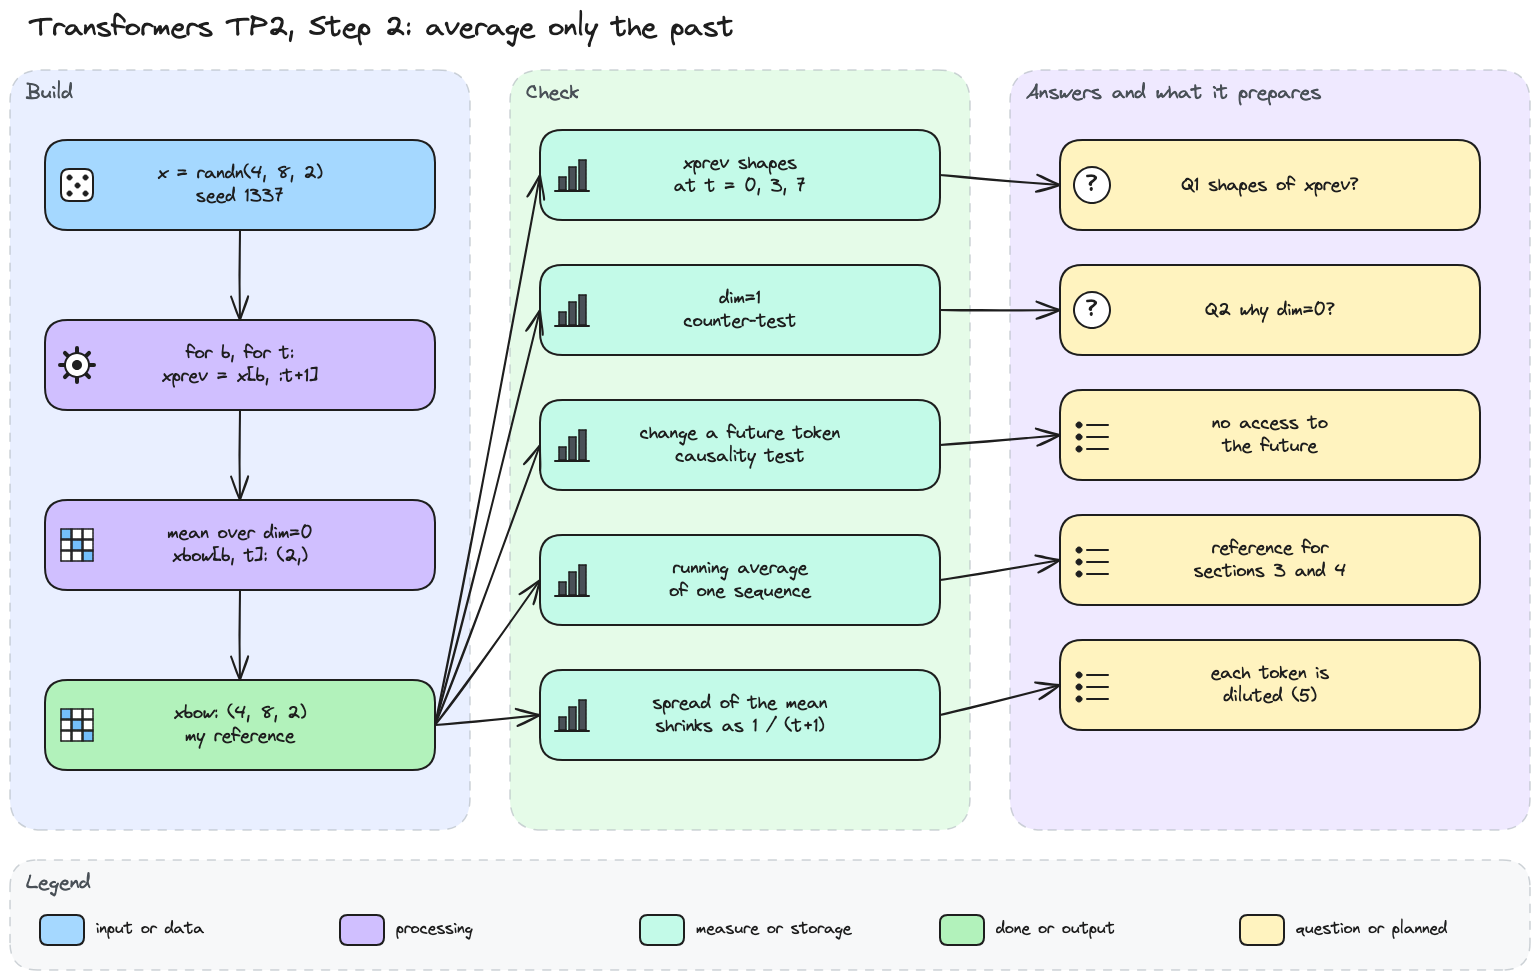

In [11]:
# Step 2 diagram: the two loops, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step2.png', width=900))

In [12]:
# The causal mean with two loops: for each sequence b and position t, the mean of x[b, :t+1].
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]  # (t+1, C)
        xbow[b, t] = torch.mean(xprev, dim=0)

print(f'x: {tuple(x.shape)}, xbow: {tuple(xbow.shape)}')
for t in (0, 3, 7):
    print(f'xprev for t = {t}: {tuple(x[0, :t + 1].shape)}')

x: (4, 8, 2), xbow: (4, 8, 2)
xprev for t = 0: (1, 2)
xprev for t = 3: (4, 2)
xprev for t = 7: (8, 2)


What shape does `xprev` have? (1, 2) at t = 0, (4, 2) at t = 3 and (8, 2) at t = 7, so t+1 rows of C = 2 channels. Each row is one visible token, so `xprev` grows by one row at each position, while `xbow` keeps the shape of `x`, (4, 8, 2). Why the mean over dim=0? Because dim=0 runs over these rows, the positions, so the mean mixes tokens and keeps the 2 channels apart.

I check what the other axis would do.

In [13]:
# What would dim=1 do? At t = 3, the mean over the channels instead of the positions.
xprev = x[0, :4]
print(f'Mean over dim=0: {tuple(xprev.mean(dim=0).shape)}, '
      f'over dim=1: {tuple(xprev.mean(dim=1).shape)}')
try:
    xbow.clone()[0, 3] = xprev.mean(dim=1)  # on a copy, so xbow stays intact
except RuntimeError as error:
    print(f'Writing it into xbow[0, 3] fails: {error}')

Mean over dim=0: (2,), over dim=1: (4,)
Writing it into xbow[0, 3] fails: The expanded size of the tensor (2) must match the existing size (4) at non-singleton dimension 0.  Target sizes: [2].  Tensor sizes: [4]


Over dim=1, the mean averages the 2 channels of each token instead, and gives 4 numbers, one per position. These numbers mix two different features of a token, and they do not fit the slot `xbow[0, 3]`, which expects 2 values, so PyTorch refuses the copy. dim=0 is the only axis that averages tokens and keeps each channel on its own.

To run the loops on other inputs, I wrap them in a function.

In [14]:
# Tools: the same two loops as a function, to run them on other inputs.
def loop_mean(x: torch.Tensor) -> torch.Tensor:
    """Causal mean with two loops: row t of each sequence is the mean of its rows 0 to t."""
    B, T, C = x.shape
    out = torch.zeros((B, T, C))
    for b in range(B):
        for t in range(T):
            out[b, t] = torch.mean(x[b, :t + 1], dim=0)
    return out


print(f'loop_mean(x) gives xbow again: {torch.equal(loop_mean(x), xbow)}')

loop_mean(x) gives xbow again: True


In [15]:
# Does a position ever read the future? Token 5 of the first sequence raised by 10, loops again.
changed = x.clone()
changed[0, 5] += 10
changed_bow = loop_mean(changed)

moves = (changed_bow[0] - xbow[0]).abs().max(dim=1).values
print(f'Largest change in each row of xbow[0]: {[round(v, 3) for v in moves.tolist()]}')
print(f'Rows 0 to 4 unchanged: {torch.equal(changed_bow[0, :5], xbow[0, :5])}')
print(f'Other sequences unchanged: {torch.equal(changed_bow[1:], xbow[1:])}')

Largest change in each row of xbow[0]: [0.0, 0.0, 0.0, 0.0, 0.0, 1.667, 1.429, 1.25]
Rows 0 to 4 unchanged: True
Other sequences unchanged: True


Raising token 5 changes nothing in rows 0 to 4, so no earlier position reads it, and the other sequences of the batch do not move either. Rows 5, 6 and 7 move by 1.667, 1.429 and 1.25, which is 10/6, 10/7 and 10/8. A token weighs 1/(t+1) in the mean at position t, as in section 1, so its influence fades as the past grows.

Next I look at what the running mean does to one sequence.

x[0], channel 0: [0.18, -0.36, 0.63, 0.95, 0.36, -1.35, 0.24, -0.92]
xbow[0], channel 0: [0.18, -0.09, 0.15, 0.35, 0.35, 0.07, 0.09, -0.03]


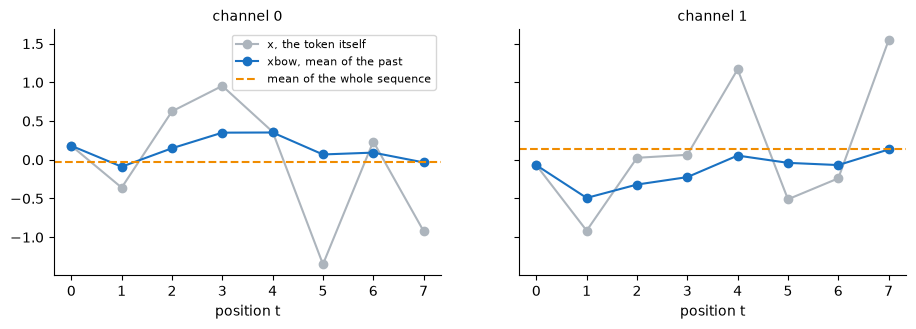

In [16]:
# What does the running mean look like? Both channels of the first sequence, x against xbow.
print(f'x[0], channel 0: {[round(v, 2) for v in x[0, :, 0].tolist()]}')
print(f'xbow[0], channel 0: {[round(v, 2) for v in xbow[0, :, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for channel, ax in enumerate(axes):
    ax.plot(range(T), x[0, :, channel], marker='o', color='#adb5bd', label='x, the token itself')
    ax.plot(range(T), xbow[0, :, channel], marker='o', color='#1971c2',
            label='xbow, mean of the past')
    ax.axhline(x[0, :, channel].mean(), color='#f08c00', linestyle='--',
               label='mean of the whole sequence')
    ax.set_xlabel('position t')
    ax.set_title(f'channel {channel}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

The first value of `xbow` copies the first token, 0.18 in channel 0, and then the mean follows the next tokens less and less. In channel 0, token 5 drops to -1.35 but the mean only goes from 0.35 to 0.07. At position 7 the mean is -0.03, exactly the mean of the whole sequence, since it averages all 8 tokens. The early positions know few tokens but see them clearly, while the last ones know every token a little.

I measure this dilution on many random sequences.

Position 0: variance 1.002, 1 / (t+1) = 1.000
Position 1: variance 0.501, 1 / (t+1) = 0.500
Position 3: variance 0.237, 1 / (t+1) = 0.250
Position 7: variance 0.124, 1 / (t+1) = 0.125


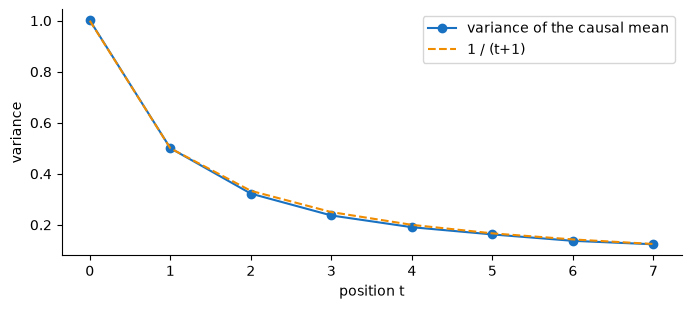

In [17]:
# How much of one token survives in the mean? Variance of the causal mean of many random sequences.
torch.manual_seed(RANDOM_STATE)
many = torch.randn(2000, T, C)
variance = loop_mean(many).var(dim=(0, 2))
for t in (0, 1, 3, 7):
    print(f'Position {t}: variance {variance[t]:.3f}, 1 / (t+1) = {1 / (t + 1):.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), variance, marker='o', color='#1971c2', label='variance of the causal mean')
ax.plot(range(T), [1 / (t + 1) for t in range(T)], linestyle='--', color='#f08c00',
        label='1 / (t+1)')
ax.set_xlabel('position t')
ax.set_ylabel('variance')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The variance of the causal mean follows 1/(t+1) closely, with 1.002 at position 0, 0.501 at position 1, 0.237 at position 3 and 0.124 at position 7. Averaging t+1 independent tokens divides their variance by t+1, so at position 7 each token keeps only an eighth of its weight. In NLP TP2 I averaged all the token vectors of a reply in the same way, with a masked mean that ignored the padding (section 2.2). Here the mean only covers the past, but it dilutes the tokens just as much. Fixed weights cannot keep an important token loud, and the learned weights of section 5 are meant to do that.

> *My conclusion:*
>
> The two loops give, for every sequence and position, the mean of the tokens up to that position, and changing a future token leaves the past untouched. The mean follows each sequence less and less, and its variance falls like 1/(t+1), so every token is diluted as the context grows. These loops are slow but simple, so `xbow` becomes my reference for the vectorised versions of sections 3 and 4.
>
> My answers to the two questions of this step:
>
> 1. `xprev` has shape (1, 2) at t = 0, (4, 2) at t = 3 and (8, 2) at t = 7, so (t+1, C).
> 2. The mean is over dim=0 because the rows of `xprev` are the positions, so it averages the tokens and keeps the C channels apart. Over dim=1 it would average the channels instead.

## 3. Vectorise with a triangular matrix

The matrix of section 1, built at size T, should give the same averages in one product. I will check it against the loops with `torch.allclose`, and see why a (T, T) matrix can multiply a (B, T, C) tensor.

## 4. The same weights from a mask and softmax

I will fill the future with −∞ and apply softmax, which should give exactly the same weights. This form matters because attention will put learned scores where the zeros are now.

## 5. Compute attention weights

Keys and queries will score how well each past token fits the current one, and the values will carry what gets mixed. I will read the weights of `wei[0]` and follow the shapes B, T, C and d_h.

## 6. Stabilise softmax

The dot product of a query and a key grows with the head size, which can make softmax put all its weight on one token. I will measure this growth and see how dividing by √d_h keeps the weights informative.

## Summary

I will check the invariant of every version, rows that sum to 1 and no weight on the future, and explain the distinct roles of Q, K and V.